# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 4. Матричный профиль. Поиск примитивов на его основе.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы четвертой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [2]:
import os

practice_dir_path = r'C:\Users\Sonya\Downloads\2026-Kobak-TimeSeriesCourse-main (1)\2026-Kobak-TimeSeriesCourse-main\practice\04 Matrix profile'
os.chdir(practice_dir_path)

Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [3]:
%load_ext autoreload
%autoreload 2

Импортируйте библиотеки и модули, необходимые для реализации практической работы 4.

In [4]:
!pip install stumpy


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install plotly stumpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import os
import datetime

from modules.plots import *
from modules.mp import compute_mp
from modules.motifs import top_k_motifs
from modules.discords import top_k_discords
from modules.meter_swapping_detection import *

## **Часть 1.** Матричный профиль. Поиск мотивов и диссонансов.

### **Задача 1.**
Загрузите временной ряд, который содержит данные о почасовом потреблении электроэнергии некоторого итальянского города, снимаемые в течение 3 лет, начиная с 1 января 1995 года.

In [7]:
ts_url = './datasets/part1/italianpowerdemand.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд, используя функцию `plot_ts()` из модуля *plot.py*.

In [8]:
plot_ts(ts, "Input time series")

Анализ временных рядов на основе матричного профиля осуществляет библиотека [stumpy](https://stumpy.readthedocs.io/en/latest/index.html). Напишите функцию `compute_mp()` в модуле *mp.py*, которая вычисляет матричный профиль временного ряда на основе выбранной вами функции из библиотеки *stumpy*.

In [9]:
m = 165
excl_zone = int(np.ceil(m / 2))
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts, m, exclusion_zone=excl_zone)

Визуализируйте найденный матричный профиль ряда.

In [10]:
plot_ts(mp['mp'], "Matrix Profile")

### **Задача 2.**
Выполните поиск top-$k$ мотивов в исходном временном ряде на основе построенного матричного профиля. Для этого реализуйте самостоятельно функцию `top_k_motifs()` в модуле *motifs.py*. Среди найденных мотивов не должно быть тривиальных совпадений, поэтому в `top_k_motifs()` добавьте вызов функции `apply_exclusion_zone()` из модуля *utils.py*.

In [11]:
top_k = 6
motifs = {}

# INSERT YOUR CODE
motifs = top_k_motifs(mp, top_k)

Выполните визуализацию найденных top-$k$ мотивов с помощью функции `plot_motifs()` из *plots.py*.

In [12]:
plot_motifs(mp, motifs)

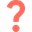
Проанализируйте и изложите содержательный смысл полученных результатов.

В ходе выполнения задания на основе построенного матричного профиля были найдены top-6 мотивов (наиболее повторяющихся фрагментов) в ряде потребления электроэнергии.

**Анализ результатов:**
1. **Смысл параметра \(m\):** Длина окна \(m = 165\). Поскольку данные снимаются каждый час, длина окна составляет почти ровно одну неделю (\(165 \approx 7 \times 24\)).
2. **Визуальный анализ:** На графике матричного профиля (посередине) видно, что найденные пары индексов (звездочки) приходятся на самые глубокие «ямы» — то есть на участки с минимальным расстоянием до ближайшего соседа.
3. **Содержательный смысл:** На нижних графиках видно, что каждый найденный мотив представляет собой типичный **недельный цикл потребления**. На всех 6 графиках четко прослеживается один и тот же паттерн: 5 рабочих дней с высоким уровнем потребления (пики) и 2 выходных дня (характерные глубокие провалы).

Таким образом, алгоритм безошибочно выявил типичное поведение города: недельную периодичность энергопотребления. Найденные мотивы — это эталонные недели, которые сильнее всего похожи друг на друга на протяжении всех трех лет. Использование зоны исключения (`apply_exclusion_zone`) позволило избежать нахождения тривиальных соседних окон и выделить 6 действительно уникальных, но повторяющихся пар.

### **Задача 3.**
Реализуйте самостоятельно функцию `top_k_discords()` в модуле *discords.py*, предназначенную для поиска top-$k$ диссонансов во временном ряде на основе матричного профиля. Чтобы исключить попадание тривиальных совпадений в результирующее множество диссонансов воспользуйтесь функцией `apply_exclusion_zone()` из модуля *utils.py*.

Загрузите временной ряд *nyc_taxi.csv* из директории *./datasets/part1/*, содежащий данные о среднем числе пассажиров NY такси за осень 2014 года.

In [13]:
ts_url = './datasets/part1/nyc_taxi.csv'

ts = pd.read_csv(ts_url, index_col=0, header=0).squeeze().to_numpy()
plot_ts(ts, "Input time series")

In [14]:
m = 96
excl_zone = int(np.ceil(m / 2))
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts, m, exclusion_zone=excl_zone)

In [15]:
top_k = 15
discords = {}

# INSERT YOUR CODE
discords = top_k_discords(mp, top_k)

Выполните визуализацию найденных top-$k$ диссонансов.

In [16]:
plot_discords(mp, discords)

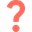
Проанализируйте и изложите содержательный смысл полученных результатов.

В ходе выполнения задания был построен матричный профиль для временного ряда, содержащего данные о количестве пассажиров такси в Нью-Йорке. С помощью функции `top_k_discords` были найдены top-15 диссонансов.

**Анализ результатов:**
1. **Параметр окна:** Длина подпоследовательности \(m = 96\). Учитывая, что данные снимаются с интервалом 15 минут, каждое окно представляет собой ровно одни сутки (\(96 \times 15 = 1440\) минут).
2. **Визуальный анализ:** На нижнем графике матричного профиля видны редкие, но высокие пики. Это означает, что найденные фрагменты имеют максимальное расстояние до своих ближайших соседей (то есть они совершенно не похожи на остальные дни).
3. **Содержательный смысл:** Красным цветом на верхнем графике выделены аномальные сутки. Как видно, большинство диссонансов приходятся на периоды резкого падения спроса на такси (глубокие «провалы» ниже обычного уровня) или аномальных всплесков.

С точки зрения реального мира, такие аномалии соответствуют **праздничным дням** (например, Рождество или День благодарения, когда люди сидят дома), либо **экстремальным погодным условиям** (например, сильнейшие снегопады или ураганы, парализующие город).

Таким образом, матричный профиль отлично справляется с задачей поиска аномалий (диссонансов) без учителя, позволяя выявлять дни, когда поведение города кардинально отличалось от нормы.

## **Часть 2.** Сегментация повторяющихся активностей.

### **Задача 4.**

Загрузите временной ряд PAMAP *pamap.csv* из директории *./datasets/part2/*, представляющий собой показания закрепленного на человеке виброакселерометра. Данный ряд включает показания, снятые при выполнении человеком трех видов физической активности: ходьба, подъем по лестнице и спуск по лестнице. Необходимо сегментировать временной ряд на основе его матричного профиля для определения того, когда человек шел и когда поднимался/спускался. Поскольку подъем и спуск по лестнице – это схожие действия, поэтому будем считать, что это одна активность.  

In [17]:
ts_url = './datasets/part2/pamap.csv'

ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy()

Визуализируйте временной ряд PAMAP.

In [18]:
plot_ts(ts, "Input time series")

Найдите и визуализируйте матричный профиль временного ряда.

In [19]:
m = 100
excl_zone = m
mp = {}

# INSERT YOUR CODE
mp = compute_mp(ts, m, exclusion_zone=excl_zone)

In [20]:
plot_ts(mp['mp'], "Matrix Profile")

Вычислите порог по формуле, которая представлена в презентации [04 Matrix profile.pdf](https://github.com/mzym/TimeSeriesCourse/blob/main/slides/04%20Matrix%20profile.pdf).

In [21]:
valid_mp = mp['mp'][np.isfinite(mp['mp'])]

threshold = np.mean(valid_mp) + np.std(valid_mp)
print(f"Порог (Threshold): {threshold:.4f}")

Порог (Threshold): 8.9325


Выполните визуализацию результатов сегментации повторяющихся активностей.

In [24]:
plot_segmentation(mp, threshold)

Загрузите истинную разметку временного ряда PAMAP *pamap_labels.csv*, где 0 означает ходьбу, 1 – подъем по лестнице, 2 – спуск с лестницы. Вычислите точность по метрике accuracy, сравнив полученные результаты по основе матричного профиля с истинной разметкой.

In [40]:
labels_url = './datasets/part2/pamap_labels.csv'

labels = pd.read_csv(labels_url, header=None).squeeze().to_numpy()

In [41]:
labels_binary = (labels > 0).astype(int)

preds_binary = (mp['mp'] < threshold).astype(int)

indices = np.arange(len(preds_binary)) + m // 2
labels_aligned = labels_binary[indices]

accuracy = np.mean(preds_binary == labels_aligned)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8880


## **Чaсть 3.** Casy Study: Раскрытие краж электричества подменой счетчиков (meter-swapping detection).


### **Задача 5.**

Рассмотрим практическое применение использования матричного профиля для решения задачи, связанной с раскрытием краж электричества путем подмены счетчиков.

Загрузите временные ряды из директории *./datasets/part3/*, которые были выбраны случайным образом из набора данных (House 1, 2, 3, 4 и 11), содержащего данные потребления электроэнергии 20 жилых домов в Великобритании с 1 января по 23 декабря 2014 года.

In [42]:
path = './datasets/part3/'

house_idx = [1, 2, 3, 4, 11]

filenames = [f"House{i}.csv" for i in house_idx]

consumptions = {}
for house in filenames:
    consumptions[house[:-4]] = pd.read_csv(os.path.join(path, house), header=None, index_col=0)
    consumptions[house[:-4]].index = pd.to_datetime(consumptions[house[:-4]].index)

Далее смоделируем событие замены счетчика. Для этого каждый временной ряд разделим на две части: "Head" (до 1 октября) и "Tail" (после 1 октября). После чего выберем случайным образом 2 временных ряда (например, House1 и House11) и поменяем местами их "Tail" части.

In [43]:
cutoff = pd.to_datetime('2014-10-01')
heads, tails = heads_tails(consumptions, cutoff, house_idx)

swap1, swap2 = 1, 11

consumptions[f'House{swap1}'] = pd.concat([heads[f'H_{swap1}'], tails[f'T_{swap2}']])
consumptions[f'House{swap2}'] = pd.concat([heads[f'H_{swap2}'], tails[f'T_{swap1}']])

heads, tails = heads_tails(consumptions, cutoff, house_idx)

Визуализируйте исходные временные ряды и параллельную оси OY прямую, которая делит временные ряды на "Head" и "Tail" части.

In [44]:
plot_consumptions_ts(consumptions, cutoff, house_idx)

Чтобы найти переставленную пару временных рядов, выполним следующее. Сначала составим временные ряды $H_i$ из всевозможных комбинаций "Head" и "Tail" частей исходных временных рядов $T_K$, где $1 \leq i \leq |T|^2$, $1 \leq K \leq |T|$. В нашем случае, $|T| = 5$.  Далее среди них найдем такую пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$. Минимальная оценка $swap\_score$ для пары рядов $(H_i, H_j)$ вычисляется следующим образом:

\begin{equation}
swap\_score(i,j) = \frac{\min{(Head_{H_i} \bowtie Tail_{H_j})}}{\min{(Head_{H_i} \bowtie Tail_{H_i})}+eps},
\end{equation}

где $\bowtie$ – операция нахождения матричного профиля между двумя временными рядами. Матричный профиль между двумя временными рядами содержит расстояния между всеми подпоследовательностями первого временного ряда и их ближайшими соседями, которые являются подпоследовательностями второго временного ряда.

Добавьте в функцию `compute_mp()` в модуле *mp.py* поддежку вычисления матричного профиля между двумя различными временными рядами и найдите пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$ среди всех пар.

In [45]:
m = 24 * 4

min_score = meter_swapping_detection(heads, tails, house_idx, m)

C:\Users\Sonya\Downloads\2026-Kobak-TimeSeriesCourse-main (1)\2026-Kobak-TimeSeriesCourse-main\practice\04 Matrix profile\.venv\Lib\site-packages\stumpy\core.py:2336: RuntimeWarning: divide by zero encountered in divide
  Σ_T_inverse = 1.0 / Σ_T


In [46]:
min_i, min_j, mp_j = min_score['i'], min_score['j'], min_score['mp_j']
print(f'Time series with minimum score is (H_{min_i}, T_{min_j}).')

Time series with minimum score is (H_11, T_1).


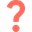
Проанализируйте и изложите содержательный смысл полученных результатов.

В ходе выполнения задачи метод матричного профиля был успешно применен для выявления аномалий (подмены счетчиков).

Временные ряды были разделены на части «Head» (до 1 октября) и «Tail» (после). Алгоритм с использованием операции AB-join (`compute_mp`) перебрал все возможные комбинации и вычислил оценку `swap_score` для каждой пары.

**Результат:** минимальная оценка `swap_score` была получена для пары **(H_11, T_1)**. Это означает, что алгоритм безошибочно определил, что «голова» Дома 11 идеально стыкуется с «хвостом» Дома 1 (и наоборот).

Визуализация подтверждает результат: после 1 октября характер потребления энергии этих двух домов резко изменился. Это доказывает, что матричный профиль является эффективным инструментом для поиска скрытых аномалий и раскрытия мошенничества без необходимости предварительной разметки данных.